<img src="images\Logo_UCLL_ENG_RGB.png" style="background-color:white;" />

# Data Analytics & Machine learning

Lecturers: Aimée Lynn Backiel, Lies Bollens, Fien Van de Woestijne

Academic year 2026-2027

## Lab 7: Classification

### Lecture outline

1. One large exercise covering all we have done so far in this course applied to classification.

### Recap of last lecture(s)

#### Lab 1

1. We ensured we had a valid Python installation.
2. We learnt what a virtual environment is:
   * Isolated Python executable and packages.
   * We created a virtual environment.
3. Absolute path vs relative path recap.
4. Recap of data structures in Python
5. Installed Pandas
6. Learnt how to read data
7. Learnt how to calculate mean, mode, median etc.
8. Basic exploration of the 4 variables

#### Lab 2
1. Wrapped up computing summary statistics (mean, median, mode, ...)
2. Learnt how to deal with outliers 
3. Focused on exploration of data

#### Lab 3
1. Univariate data visualization using Matplotlib
   1. Figures and axes
   2. Histograms
   3. Box plots
   4. Bar charts
2. Multivariate data visualization using Seaborn
   1. Scatter plots
   2. Small multiples
   3. Color coding

#### Lab 4
1. Intro to machine learning using scikit-learn
   1. Preprocessing
      1. One Hot encoding
      2. Scaling
      3. Outliers
   2. Regression

#### Lab 5
1. Preprocessing with scikit-learn
   1. ColumnTransformer: Apply a transformation to specific columns.
   2. Pipeline: Do several transformations after each other
2. Evaluation:
   1. Why the mean of the error is a bad idea
   2. Mean absolute error
   3. Mean squared error

### Lab 6
1. Feature engineering
   1. Binning
   2. Interactions
   3. Custom features
2. Rounding up model evaluation
   1. Cross validation
   2. Hyper parameter tuning

## Business understanding

#### Our next case: Hotel booking dataset

source: https://www.sciencedirect.com/science/article/pii/S2352340918315191

*This data article describes two datasets with hotel demand data. One of the hotels (H1) is a resort hotel and the other is a city hotel (H2). Both datasets share the same structure, with 31 variables describing the 40,060 observations of H1 and 79,330 observations of H2. Each observation represents a hotel booking. Both datasets comprehend bookings due to arrive between the 1st of July of 2015 and the 31st of August 2017, including bookings that effectively arrived and bookings that were canceled. Both hotels are located in Portugal: H1 at the resort region of Algarve and H2 at the city of Lisbon.*

The goal is to help the two hotels maximize their revenue.



|variable                       |class     |description |
|:------------------------------|:---------|:-----------|
|hotel                          |character | Hotel (H1 = Resort Hotel or H2 = City Hotel) |
|is_canceled                    |double    | Value indicating if the booking was canceled (1) or not (0) |
|lead_time                      |double    | Number of days that elapsed between the entering date of the booking into the PMS and the arrival date |
|arrival_date_year              |double    | Year of arrival date|
|arrival_date_month             |character | Month of arrival date|
|arrival_date_week_number       |double    | Week number of year for arrival date|
|arrival_date_day_of_month      |double    | Day of arrival date|
|stays_in_weekend_nights        |double    | Number of weekend nights (Saturday or Sunday) the guest stayed or booked to stay at the hotel |
|stays_in_week_nights           |double    |  Number of week nights (Monday to Friday) the guest stayed or booked to stay at the hotel|
|adults                         |double    | Number of adults|
|children                       |double    | Number of children|
|babies                         |double    |Number of babies |
|meal                           |character | Type of meal booked. Categories are presented in standard hospitality meal packages: <br> Undefined/SC – no meal package;<br>BB – Bed & Breakfast; <br> HB – Half board (breakfast and one other meal – usually dinner); <br> FB – Full board (breakfast, lunch and dinner) |
|country                        |character | Country of origin. Categories are represented in the ISO 3155–3:2013 format |
|market_segment                 |character | Market segment designation. In categories, the term “TA” means “Travel Agents” and “TO” means “Tour Operators” |
|distribution_channel           |character | Booking distribution channel. The term “TA” means “Travel Agents” and “TO” means “Tour Operators” |
|is_repeated_guest              |double    | Value indicating if the booking name was from a repeated guest (1) or not (0) |
|previous_cancellations         |double    | Number of previous bookings that were cancelled by the customer prior to the current booking |
|previous_bookings_not_canceled |double    | Number of previous bookings not cancelled by the customer prior to the current booking |
|reserved_room_type             |character | Code of room type reserved. Code is presented instead of designation for anonymity reasons |
|assigned_room_type             |character | Code for the type of room assigned to the booking. Sometimes the assigned room type differs from the reserved room type due to hotel operation reasons (e.g. overbooking) or by customer request. Code is presented instead of designation for anonymity reasons |
|booking_changes                |double    | Number of changes/amendments made to the booking from the moment the booking was entered on the PMS until the moment of check-in or cancellation|
|deposit_type                   |character | Indication on if the customer made a deposit to guarantee the booking. This variable can assume three categories:<br>No Deposit – no deposit was made;<br>Non Refund – a deposit was made in the value of the total stay cost;<br>Refundable – a deposit was made with a value under the total cost of stay. |
|agent                          |character | ID of the travel agency that made the booking |
|company                        |character | ID of the company/entity that made the booking or responsible for paying the booking. ID is presented instead of designation for anonymity reasons |
|days_in_waiting_list           |double    | Number of days the booking was in the waiting list before it was confirmed to the customer |
|customer_type                  |character | Type of booking, assuming one of four categories:<br>Contract - when the booking has an allotment or other type of contract associated to it;<br>Group – when the booking is associated to a group;<br>Transient – when the booking is not part of a group or contract, and is not associated to other transient booking;<br>Transient-party – when the booking is transient, but is associated to at least other transient booking|
|adr                            |double    | Average Daily Rate as defined by dividing the sum of all lodging transactions by the total number of staying nights |
|required_car_parking_spaces    |double    | Number of car parking spaces required by the customer |
|total_of_special_requests      |double    | Number of special requests made by the customer (e.g. twin bed or high floor)|
|reservation_status             |character | Reservation last status, assuming one of three categories:<br>Canceled – booking was canceled by the customer;<br>Check-Out – customer has checked in but already departed;<br>No-Show – customer did not check-in and did inform the hotel of the reason why |
|reservation_status_date        |double    | Date at which the last status was set. This variable can be used in conjunction with the ReservationStatus to understand when was the booking canceled or when did the customer checked-out of the hotel|





## Data understanding

#### ❓ Go back to lab 2. Read in the H1 and H2 dataset. What was the very first step when working with a dataset? Execute that one. Make sure the necessary packages are installed and imported.

In [1]:
import warnings
# sklearn geeft veel FutureWarnings over LogisticRegressionCV die voor ons niet relevant zijn
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

h1 = pd.read_csv("data/H1.csv")
h2 = pd.read_csv("data/H2.csv")

In [2]:
# Eerste stap uit labo 2: kijken hoe de data eruitziet
h1.head()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,342,2015,July,27,1,0,0,2,0,...,No Deposit,NULL,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,0,737,2015,July,27,1,0,0,2,0,...,No Deposit,NULL,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,0,7,2015,July,27,1,0,1,1,0,...,No Deposit,NULL,NULL,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,0,13,2015,July,27,1,0,1,1,0,...,No Deposit,304,NULL,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,0,14,2015,July,27,1,0,2,2,0,...,No Deposit,240,NULL,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
h1.info()

<class 'pandas.DataFrame'>
RangeIndex: 40060 entries, 0 to 40059
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   40060 non-null  int64  
 1   LeadTime                     40060 non-null  int64  
 2   ArrivalDateYear              40060 non-null  int64  
 3   ArrivalDateMonth             40060 non-null  str    
 4   ArrivalDateWeekNumber        40060 non-null  int64  
 5   ArrivalDateDayOfMonth        40060 non-null  int64  
 6   StaysInWeekendNights         40060 non-null  int64  
 7   StaysInWeekNights            40060 non-null  int64  
 8   Adults                       40060 non-null  int64  
 9   Children                     40060 non-null  int64  
 10  Babies                       40060 non-null  int64  
 11  Meal                         40060 non-null  str    
 12  Country                      39596 non-null  str    
 13  MarketSegment              

#### ❓ The next thing we need to decide on, is what we want to do with this dataset. We have many different variables and thus things we can do. What would you do with this dataset?

Er zijn verschillende dingen mogelijk met deze dataset. Een hotel verliest veel geld als een kamer op het laatste moment geannuleerd wordt en dus leeg blijft. Daarom lijkt het mij het nuttigst om **te voorspellen welke boekingen geannuleerd zullen worden**. Dan kan het hotel bijvoorbeeld gericht overboeken of een aanbetaling vragen.

Andere opties: de prijs per nacht (ADR) voorspellen, of klanten in groepen verdelen.

We can think of multiple things to do with this set:
1. Finding out who cancels reservations (classifcation)
2. Finding groups in the customers (clustering)
3. Predicting the amount of rooms to be booked on a given day (regression)
4. ...

We will focus in this lab on finding out who cancels their reservation. This means we will be **predicting a categorical value**. `isCanceled` is a number but in our dataset it should be regarded as a discrete category. This is called **classification**. When doing classification we will need slightly different machine learning models but most importantly, we will need different evaluation metrics. The full details are discussed in the theory sessions.

We still start of by doing exploring the dataset using Pandas exclusively and move on to some plots later on. The choice of which tool to use is yours. Start by combining both dataset in to one set called 'hotel_df'. Make sure to indicate which data is coming from which hotel.

In [4]:
# Kolom toevoegen zodat we na het samenvoegen nog weten van welk hotel een boeking komt
h1["Hotel"] = "Resort Hotel"
h2["Hotel"] = "City Hotel"

hotel = pd.concat((h1, h2), ignore_index=True)
hotel.shape

(119390, 32)

### Data understanding

#### ❓ First, take a general look at the data. Are there any missing values? Are there any values that do not make sense. Make sure to handle these missing values appropriatly. Then formulate and anwser at least 3 business questions that you think are interesting. Focus on one variable at the time. Use plots as well as metrics to study these variables.
An example of a possible business question might be: "Which countries are our guests coming from?". In a later stage, you could look at the relationship between country of origin and the cancellations. Create your own code and markdown cells. Make sure to explain/document everything you do.

In [5]:
hotel["Children"] = hotel["Children"].fillna(0)
hotel["Children"] = hotel["Children"].astype(int)

print(hotel["Children"].mean())
print(hotel["Adults"].mean())

0.10388642264846303
1.8564033838679956


In [6]:
# Oplossing van de lector
hotel.isnull().sum()
null_mapping = {"Children": 0, "Country": "Unknown"}
# hotel.fillna(null_mapping, inplace=True)
hotel = hotel.fillna(null_mapping)
hotel.describe()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,BookingChanges,DaysInWaitingList,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103886,0.007949,0.031912,0.087118,0.137097,0.221124,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398555,0.097436,0.175767,0.844336,1.497437,0.652306,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,391.000000,5400.000000,8.000000,5.000000


<Axes: ylabel='ADR'>

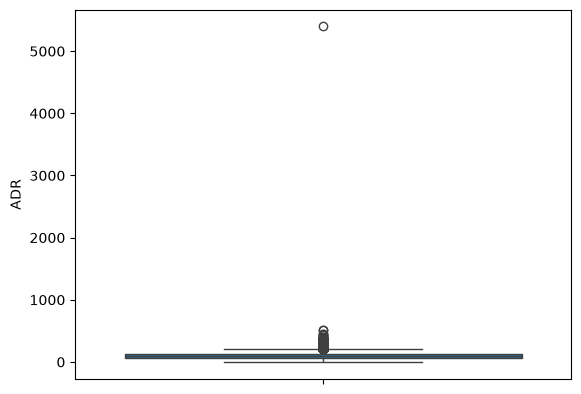

In [7]:
# Opvolging van oplossing van de lector
hotel[hotel["ADR"] > 1000]
import seaborn as sns
sns.boxplot(hotel["ADR"])

<Axes: ylabel='Adults'>

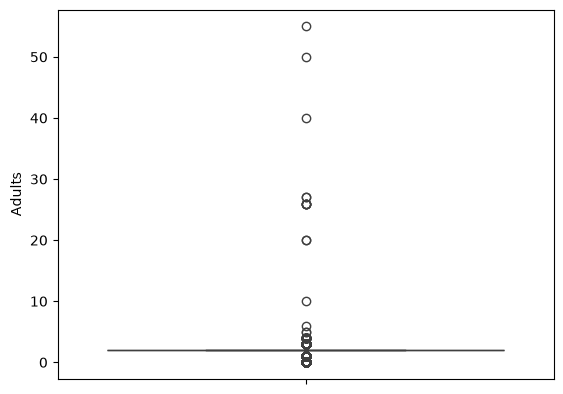

In [8]:
# Opvolging op opvolging
hotel = hotel[hotel["ADR"] < 1000]
sns.boxplot(hotel["Adults"]) # toont aan dat veel adults in één boeking geen uitschieter is

       IsCanceled  LeadTime  ArrivalDateYear ArrivalDateMonth  \
46619           0        37             2016          January   

       ArrivalDateWeekNumber  ArrivalDateDayOfMonth  StaysInWeekendNights  \
46619                      3                     12                     0   

       StaysInWeekNights  Adults  Children  ...        Agent      Company  \
46619                  2       2         0  ...            9         NULL   

      DaysInWaitingList CustomerType    ADR  RequiredCarParkingSpaces  \
46619                 0    Transient  84.45                         0   

       TotalOfSpecialRequests  ReservationStatus ReservationStatusDate  \
46619                       1          Check-Out            2016-01-14   

            Hotel  
46619  City Hotel  

[1 rows x 32 columns]


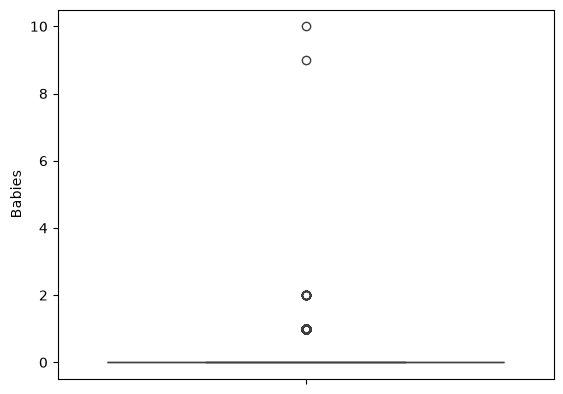

In [9]:
# Opvolging
sns.boxplot(hotel["Babies"]) # toont aan dat veel baby's in één boeking geen uitschieter is
hotel["Babies"]
print(hotel[hotel["Babies"] == 10])

In [10]:
# Laatste opvolging
hotel["IsCanceled"].value_counts()

IsCanceled
0    75166
1    44223
Name: count, dtype: int64

**Ontbrekende en vreemde waarden**
* `Children` had 4 ontbrekende waarden. Die zetten we op 0, want waarschijnlijk waren er gewoon geen kinderen.
* `Country` had 488 ontbrekende waarden. Die vervangen we door `"Unknown"`, zodat we die boekingen niet moeten weggooien.
* Er was één boeking met een ADR van meer dan 5000 euro per nacht. Dat is waarschijnlijk een tikfout, dus die rij laten we weg.
* Er waren boekingen met heel veel volwassenen of 10 baby's. Dat lijkt raar, maar het zijn er maar een paar en het kan om groepen gaan. Die laten we staan.
* Ongeveer 37% van alle boekingen wordt geannuleerd. De klassen zijn dus niet helemaal in evenwicht, maar ook niet extreem scheef.

##### Vraag 1: Uit welke landen komen onze gasten?

In [11]:
top_countries = hotel["Country"].value_counts().head(10)
px.bar(top_countries, title="Top 10 landen van herkomst")

In [12]:
(hotel["Country"].value_counts(normalize=True).head(5) * 100).round(1)

Country
PRT    40.7
GBR    10.2
FRA     8.7
ESP     7.2
DEU     6.1
Name: proportion, dtype: float64

##### Vraag 2: Hoe lang op voorhand boeken gasten?

In [13]:
hotel["LeadTime"].describe()

count    119389.000000
mean        104.011994
std         106.863358
min           0.000000
25%          18.000000
50%          69.000000
75%         160.000000
max         737.000000
Name: LeadTime, dtype: float64

In [14]:
px.histogram(hotel, x="LeadTime", nbins=60, title="Aantal dagen tussen boeking en aankomst")

##### Vraag 3: In welke maanden komen de meeste gasten?

In [15]:
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
bookings_per_month = hotel["ArrivalDateMonth"].value_counts().reindex(month_order)
px.bar(bookings_per_month, title="Aantal boekingen per aankomstmaand")

**Conclusies univariate analyse**
1. **Herkomst**: ongeveer 41% van de gasten komt uit Portugal zelf, gevolgd door het VK (10%), Frankrijk (9%), Spanje (7%) en Duitsland (6%). Het zijn dus vooral Europese gasten.
2. **Lead time**: de mediaan is 69 dagen, maar de verdeling is erg scheef naar rechts. De meeste mensen boeken een paar weken op voorhand, maar sommigen meer dan een jaar (max 737 dagen).
3. **Maanden**: de zomer (juli en augustus) is het drukst, de winter (november–januari) het rustigst. Augustus heeft meer dan het dubbele aantal boekingen van januari.

#### ❓ Now, move on to a bivariate or multivariate analysis: looking at the relationship between two or more of the variables at the same time. Again, start by formulating questions and answer them. Keep in mind that we want to figure out why people cancel their holidays.

In [16]:
# Cancellations per country
top_20_countries = hotel["Country"].value_counts().sort_values(ascending=False).iloc[:20]
country_subset = hotel[hotel["Country"].isin(top_20_countries.index)] #...
px.histogram(country_subset, x="Country", color="IsCanceled", barmode="group") #...

Het aantal boekingen per land toont vooral dat er veel Portugezen zijn. Om eerlijk te vergelijken kijken we naar het **percentage** annulaties per land.

In [17]:
cancel_rate_country = country_subset.groupby("Country")["IsCanceled"].mean().sort_values(ascending=False)
px.bar(cancel_rate_country, title="Percentage geannuleerde boekingen per land (top 20 landen)")

##### Vraag 4: Wordt er in het ene hotel meer geannuleerd dan in het andere?

In [18]:
hotel.groupby("Hotel")["IsCanceled"].mean()

Hotel
City Hotel      0.417262
Resort Hotel    0.277634
Name: IsCanceled, dtype: float64

##### Vraag 5: Annuleren mensen die lang op voorhand boeken vaker?

In [19]:
px.box(hotel, x="IsCanceled", y="LeadTime", title="Lead time voor geannuleerde (1) en niet-geannuleerde (0) boekingen")

##### Vraag 6: Heeft het type aanbetaling en het marktsegment invloed op annulaties?

In [20]:
deposit_summary = hotel.groupby("DepositType")["IsCanceled"].agg(["mean", "size"])
deposit_summary.columns = ["percentage geannuleerd", "aantal boekingen"]
deposit_summary

,percentage geannuleerd,aantal boekingen
DepositType,,
No Deposit,0.283770,104641
Non Refund,0.993624,14586
Refundable,0.222222,162


In [21]:
segment_rate = hotel.groupby("MarketSegment")["IsCanceled"].mean().sort_values(ascending=False)
px.bar(segment_rate, title="Percentage geannuleerde boekingen per marktsegment")

##### Vraag 7: Annuleren gasten met speciale verzoeken of een parkeerplaats minder?

In [22]:
hotel.groupby("TotalOfSpecialRequests")["IsCanceled"].agg(["mean", "size"])

,mean,size
TotalOfSpecialRequests,,
0,0.477196,70317
1,0.220249,33226
2,0.220989,12969
3,0.178614,2497
4,0.105882,340
5,0.050000,40


**Conclusies bivariate analyse**
* **Land**: Portugese gasten annuleren veel vaker (57%) dan bv. Duitse, Franse of Britse gasten (±20%). Mogelijk boeken binnenlandse gasten makkelijker "voor de zekerheid".
* **Hotel**: in het City Hotel wordt meer geannuleerd (42%) dan in het Resort Hotel (28%).
* **Lead time**: geannuleerde boekingen zijn gemiddeld veel langer op voorhand gemaakt (mediaan 113 dagen tegenover 45 dagen). Hoe langer op voorhand, hoe meer kans dat de plannen nog veranderen.
* **Aanbetaling**: opvallend genoeg wordt bijna **99%** van de boekingen met een *niet-terugbetaalbare* aanbetaling geannuleerd. Dat lijkt onlogisch, maar als je die boekingen bekijkt zijn het bijna allemaal groepen (63%) of boekingen via touroperators (34%), en bij 97% staat Portugal als land. Waarschijnlijk zijn dat blokken kamers die op voorhand gereserveerd en later vrijgegeven worden. Dat verklaart meteen ook een deel van het hoge annulatiepercentage van Portugal. Het blijft wel een heel sterke voorspeller.
* **Marktsegment**: groepen annuleren het vaakst (61%), directe en zakelijke boekingen het minst (15–19%).
* **Speciale verzoeken**: gasten zonder speciale verzoeken annuleren in 48% van de gevallen, met één of meer verzoeken nog maar ±22% of minder. Wie moeite doet om iets te vragen, is van plan om te komen.

#### ❓ Finally, let's check which variables are highly correlated with cancellations
(hint use numeric_only=True when making the correlations, that way you don't have to type out all numeric columns)

<Axes: >

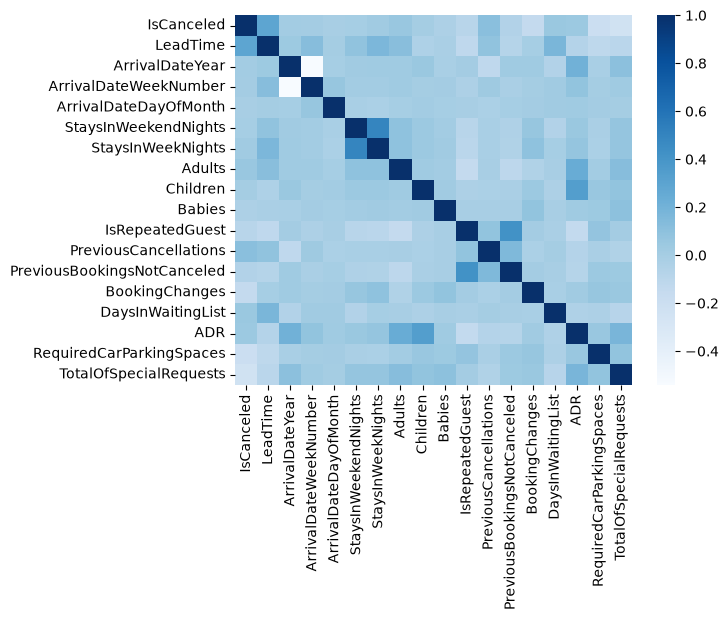

In [23]:
sns.heatmap(hotel.corr(numeric_only=True), cmap="Blues")

De numerieke variabelen die het sterkst samenhangen met `IsCanceled` zijn:
* `LeadTime` (+0.29): hoe langer op voorhand geboekt, hoe meer annulaties.
* `TotalOfSpecialRequests` (-0.24) en `RequiredCarParkingSpaces` (-0.20): wie speciale verzoeken heeft of een parkeerplaats vraagt, annuleert minder.
* `BookingChanges` (-0.14) en `PreviousCancellations` (+0.11).

Geen enkele variabele is op zich héél sterk gecorreleerd. We zullen dus een combinatie van variabelen nodig hebben. Let op: deze heatmap bevat enkel numerieke kolommen. Belangrijke categorische kolommen zoals `DepositType` zitten er (nog) niet in.

## Data Preparation

#### ❓Go back to lab 5 and 6 and take another look on how to prepare your data for modeling. The same steps are needed for classification as for regression. Take the necessary steps below. Make your own code and markdown cells.
We suggest calling your final prepocessor 'preprocessor' so the code below still works. Otherwise, you will have to update

#### Opkuisen van de tekstkolommen

Sommige tekstkolommen hebben extra spaties (bv. `"BB       "`) en bij `Agent` en `Company` staat er `"NULL"` als tekst in plaats van een echte lege waarde. Dat kuisen we eerst op.

In [24]:
text_columns = hotel.select_dtypes(include="str").columns
for column in text_columns:
    hotel[column] = hotel[column].str.strip()

hotel["Meal"].value_counts()

Meal
BB           92309
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

#### Welke kolommen gebruiken we?

* **Weglaten wegens data leakage**: `ReservationStatus` en `ReservationStatusDate` zeggen letterlijk of iemand geannuleerd heeft (status "Canceled"). Die informatie heb je niet op het moment dat je een voorspelling wilt maken.
* `AssignedRoomType` laten we ook weg: de kamer wordt pas definitief toegewezen bij het inchecken. Boekingen waar die verschilt van de gereserveerde kamer worden bijna nooit geannuleerd (5% tegenover 42%), maar dat komt omdat de gast er al *is*. Dat is dus ook leakage.
* `Agent` en `Company` zijn ID's met honderden waarden. In plaats daarvan maken we een feature of er een agent of bedrijf bij de boeking betrokken was.
* `ArrivalDateYear` laten we weg: we willen voorspellingen maken voor toekomstige jaren, die het model nooit gezien heeft.
* Nieuwe feature `TotalNights` = weekend- + weekdagnachten.

In [25]:
hotel["HasAgent"] = hotel["Agent"] != "NULL"
hotel["HasCompany"] = hotel["Company"] != "NULL"
hotel["TotalNights"] = hotel["StaysInWeekendNights"] + hotel["StaysInWeekNights"]

leakage_columns = ["ReservationStatus", "ReservationStatusDate", "AssignedRoomType"]
other_dropped = ["Agent", "Company", "ArrivalDateYear"]

X = hotel.drop(columns=["IsCanceled"] + leakage_columns + other_dropped)
y = hotel["IsCanceled"]

# stratify=y zorgt dat train en test hetzelfde percentage annulaties hebben
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=42, stratify=y)
print(f"{len(X_train) = } and {len(X_test) = }")
print(f"Percentage geannuleerd in train: {y_train.mean():.3f}, in test: {y_test.mean():.3f}")

len(X_train) = 95511 and len(X_test) = 23878
Percentage geannuleerd in train: 0.370, in test: 0.370


In [26]:
numeric_columns = ["LeadTime", "ArrivalDateWeekNumber", "ArrivalDateDayOfMonth", "StaysInWeekendNights",
                   "StaysInWeekNights", "TotalNights", "Adults", "Children", "Babies", "IsRepeatedGuest",
                   "PreviousCancellations", "PreviousBookingsNotCanceled", "BookingChanges",
                   "DaysInWaitingList", "ADR", "RequiredCarParkingSpaces", "TotalOfSpecialRequests"]
cat_columns = ["Hotel", "ArrivalDateMonth", "Meal", "Country", "MarketSegment", "DistributionChannel",
               "ReservedRoomType", "DepositType", "CustomerType", "HasAgent", "HasCompany"]

# Country heeft meer dan 170 landen: landen met minder dan 100 boekingen worden samengenomen
# in één "infrequent" kolom. handle_unknown zorgt dat een nieuw land in de testset geen fout geeft.
preprocessor = make_column_transformer(
    (StandardScaler(), numeric_columns),
    (OneHotEncoder(sparse_output=False, min_frequency=100, handle_unknown="infrequent_if_exist"), cat_columns),
    remainder="drop"
)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardscaler', ...), ('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name``

#### ❓Below, we have added some code that allows you to study the correlation of the variables after preprocessing. Take a look, what changed?

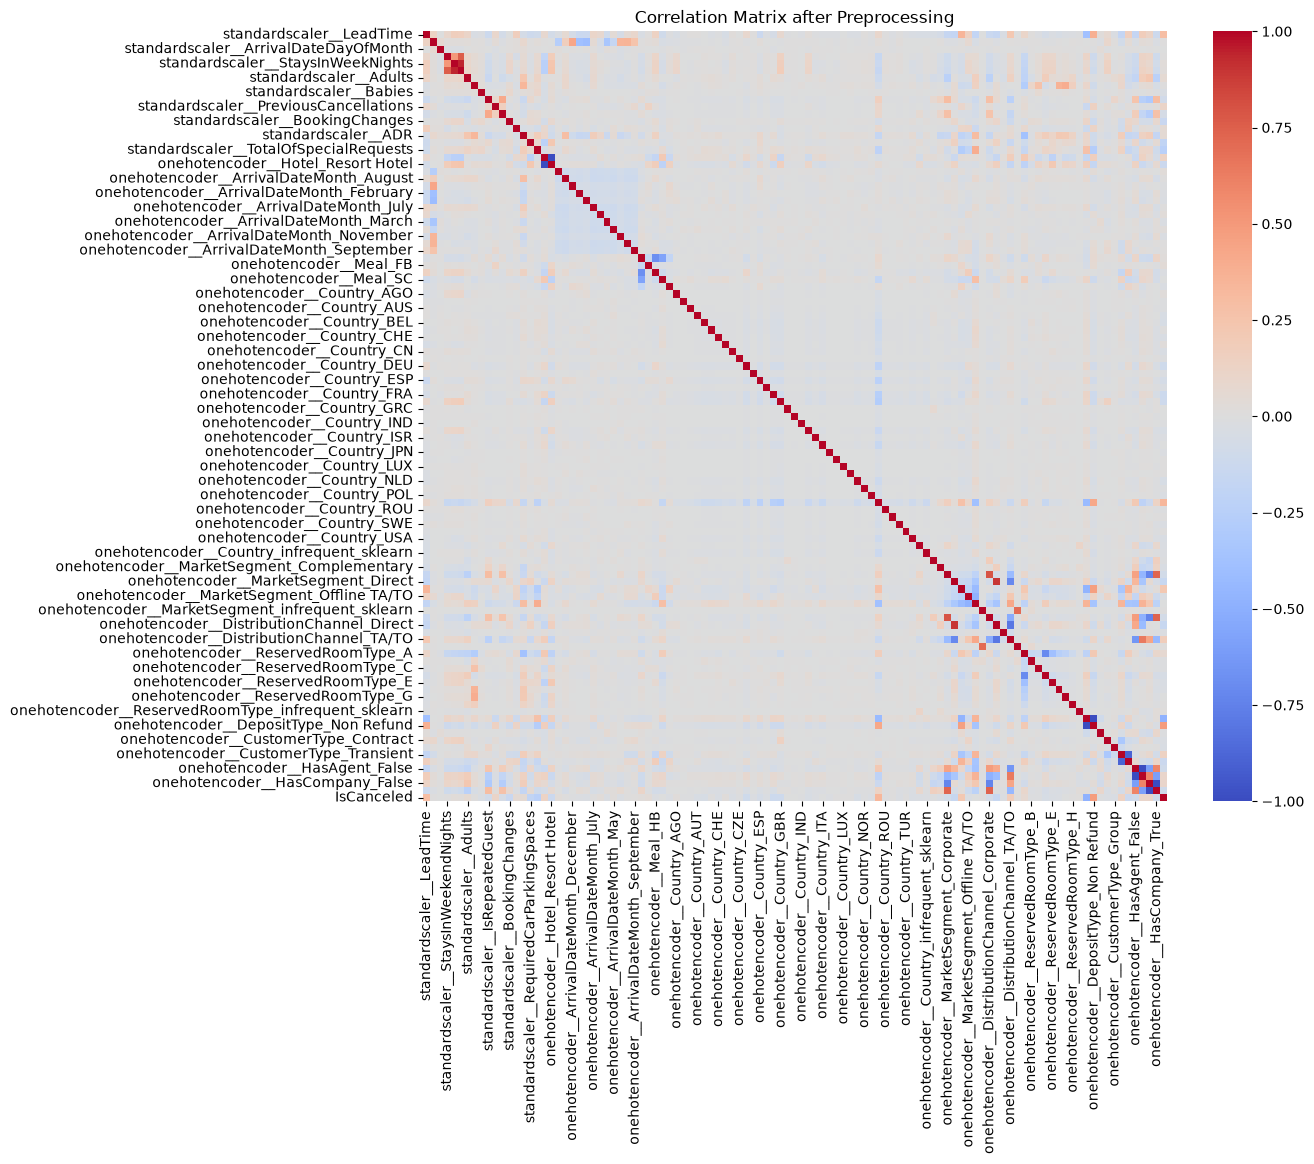

In [27]:
# 1. Fit the preprocessor on your training data
preprocessor.fit(X_train)

# 2. Transform the data
X_processed = preprocessor.transform(X_train)

# 3. Convert to a DataFrame
#    If your preprocessor includes ColumnTransformer with named columns, you can get feature names
feature_names = preprocessor.get_feature_names_out()
X_processed_df = pd.DataFrame(X_processed, columns=feature_names)
# Add IsCancelled back
X_processed_df["IsCanceled"] = y_train.values

# 4. Compute the correlation matrix
corr_matrix = X_processed_df.corr()

# 5. (Optional) visualize or inspect correlations
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0)
plt.title("Correlation Matrix after Preprocessing")
plt.show()

In [28]:
abs(X_processed_df.corr(numeric_only=True)['IsCanceled']).sort_values(ascending=False)

IsCanceled                               1.000000
onehotencoder__DepositType_Non Refund    0.482384
onehotencoder__DepositType_No Deposit    0.478684
onehotencoder__Country_PRT               0.336140
standardscaler__LeadTime                 0.292662
                                           ...   
onehotencoder__ReservedRoomType_G        0.001490
standardscaler__StaysInWeekendNights     0.001441
onehotencoder__Country_RUS               0.000739
onehotencoder__Country_BRA               0.000502
onehotencoder__Meal_SC                   0.000453
Name: IsCanceled, Length: 107, dtype: float64

Na de preprocessing zijn de categorische variabelen one-hot encoded, en daardoor kunnen we nu ook hun correlatie met `IsCanceled` zien. De sterkste verbanden zijn nu `DepositType_Non Refund` en `DepositType_No Deposit` (±0.48), sterker dan elke numerieke variabele. Daarna volgen `Country_PRT` (0.34) en pas dan `LeadTime` (0.29).

De numerieke kolommen zijn geschaald, maar hun correlatie verandert daardoor niet (correlatie is ongevoelig voor schalen). Het belangrijkste verschil is dus dat we nu de categorische variabelen mee kunnen vergelijken.

## Modeling

#### ❓Take a look at the lecture slides. Which classification models have we seen in class? In a next step, we'll try to fit and evaluate all of those. Make sure to import them here.

In de les zagen we logistische regressie, decision trees, random forests en gradient boosting. Bij classificatie gebruiken we de `Classifier`-versies in plaats van de `Regressor`-versies.

In [29]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

In a next step, we'll fit different classification models and use cross validation to improve our models. We'll look at the average accuracy of these models.

### ❗ The parameter n_jobs specifies how many cross validations can be ran in parallel. Make sure to use n_jobs = -1 when doing cross validation.  This will allow you to run as many jobs simultanously as possible. Training these models can take a while.

In [30]:
model_name_pair = [("logistic_regression", LogisticRegressionCV(max_iter=1000)), ("random_forest", RandomForestClassifier(random_state=42)), ("gradient boosting", HistGradientBoostingClassifier(random_state=42)), ("decision tree", DecisionTreeClassifier(random_state=42)) ]
pipes = []
for pair in model_name_pair:
    name, model = pair
    print(f"STARTING {name}")
    pipe = make_pipeline(preprocessor, model)
    pipes.append(pipe)
    results_acc = cross_val_score(pipe, X_train, y_train, cv=4, scoring="accuracy", n_jobs=-1)
    print("-"*20)
    print(f"The accuracy on the training set is {np.mean(results_acc)}\n")

STARTING logistic_regression


--------------------
The accuracy on the training set is 0.8125451325120001

STARTING random_forest


--------------------
The accuracy on the training set is 0.8792494991966868

STARTING gradient boosting


--------------------
The accuracy on the training set is 0.8577545758521623

STARTING decision tree


--------------------
The accuracy on the training set is 0.8365423991348464



Repeat this process, but now with roc_auc as scoring metric. 

In [31]:
# Functie uit labo 6, aangepast: zonder de country_map stap en met de pipelines van hierboven
def cross_validate_models(models: dict, preprocessors: dict, X, y, scoring: str, cv: int = 5) -> pd.DataFrame:
    """Doet cross validation voor elke combinatie van preprocessing en model.
    Geeft per combinatie het gemiddelde en de standaardafwijking van de scores terug."""
    rows = []
    for prep_name, prep in preprocessors.items():
        for model_name, model in models.items():
            pipe = make_pipeline(prep, model)
            scores = cross_val_score(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)
            rows.append({"preprocessing": prep_name, "model": model_name,
                         "mean": np.mean(scores), "std": np.std(scores)})
    return pd.DataFrame(rows)


models = dict(model_name_pair)
roc_results = cross_validate_models(models, {"preprocessor": preprocessor}, X_train, y_train,
                                    scoring="roc_auc", cv=4)
roc_results.sort_values("mean", ascending=False)

,preprocessing,model,mean,std
1,preprocessor,random_forest,0.948500,0.000602
2,preprocessor,gradient boosting,0.934532,0.000528
0,preprocessor,logistic_regression,0.889625,0.001828
3,preprocessor,decision tree,0.828042,0.001764


## Evaluating

### ❓ Motivate which model is the best and use it on the final part of the data


| model | accuracy (CV) | ROC AUC (CV) |
|---|---|---|
| logistic regression | 0.813 | 0.890 |
| random forest | **0.879** | **0.949** |
| gradient boosting | 0.858 | 0.935 |
| decision tree | 0.837 | 0.828 |

**Random forest** scoort het best op beide metrieken. De standaardafwijking over de folds is heel klein (±0.001), dus het verschil met de andere modellen is geen toeval. We kiezen daarom `pipes[1]` als finaal model.

Accuracy alleen is niet genoeg: 63% van de boekingen wordt niet geannuleerd, dus een model dat altijd "niet geannuleerd" zegt haalt al 63% accuracy. De ROC AUC kijkt naar hoe goed het model geannuleerde en niet-geannuleerde boekingen uit elkaar houdt, over alle mogelijke drempels heen. De decision tree illustreert dat: zijn accuracy is nog redelijk, maar zijn AUC is veel lager, omdat een enkele boom bijna altijd een kans van 0 of 1 geeft.

In [32]:
from sklearn.metrics import accuracy_score

In [33]:
# Fit the final model. Chose the best mode from 'pipes' above, pipes[0] being the logistic regression model and so on.
rf_pipe = pipes[1]
rf_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](28,)","['LeadTime','ArrivalDateMonth','ArrivalDateWeekNumber',...,'HasAgent', 'HasCompany','TotalNights']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardscaler', ...), ('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (

In [34]:
# Make your predictions
y_pred = rf_pipe.predict(X_test)
y_pred

array([0, 0, 1, ..., 0, 1, 0], shape=(23878,))

In [35]:
# Calculate the final accuracy

accuracy_score(y_test, y_pred)

0.8845799480693526

Finally, let's add a visualisation of the confusion matrix and roc curve:

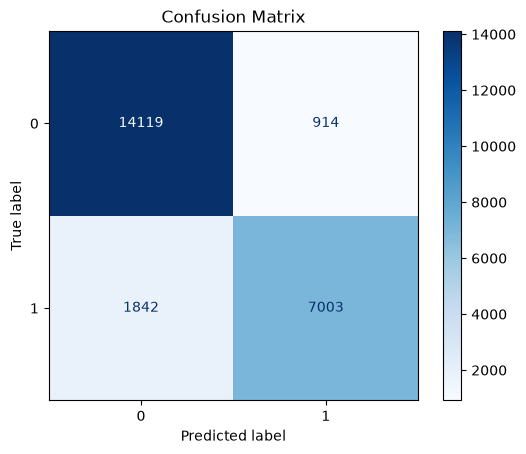

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

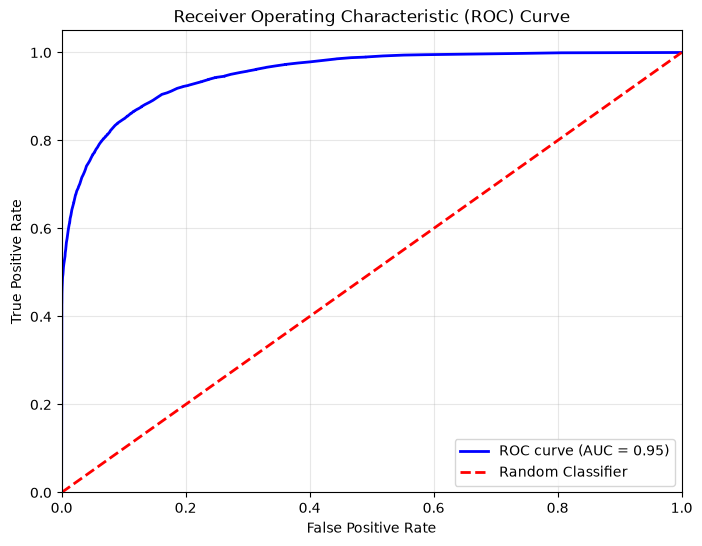

In [37]:
from sklearn.metrics import roc_curve, auc

# 1. Get predicted probabilities for the positive class
y_prob = rf_pipe.predict_proba(X_test)[:, 1]

# 2. Compute FPR, TPR and thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# 3. Compute AUC
roc_auc = auc(fpr, tpr)

# 4. Plot ROC curve
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

* **Accuracy op de testset: 0.885**, in lijn met de cross validation (0.879). Het model overfit dus niet op een manier die we niet verwacht hadden.
* **Confusion matrix** (23 878 boekingen in de testset):
  * 14 119 correct als "niet geannuleerd" voorspeld (true negatives)
  * 7 003 annulaties correct voorspeld (true positives)
  * 914 keer voorspeld dat iemand annuleert, terwijl die toch kwam (false positives)
  * 1 842 annulaties die het model gemist heeft (false negatives)
* **Precision** = 7003 / (7003 + 914) ≈ **0.88**: als het model zegt "deze boeking wordt geannuleerd", klopt dat in 88% van de gevallen.
* **Recall** = 7003 / (7003 + 1842) ≈ **0.79**: het model vindt ongeveer 79% van alle annulaties.
* **ROC AUC = 0.95**: de curve zit dicht tegen de linkerbovenhoek, veel beter dan de rode lijn van een willekeurige gok (AUC 0.5).

**Voor het hotel**: een false positive is het duurst. Als het hotel op basis van het model een kamer overboekt en de gast komt toch, dan heb je een gast zonder kamer. Het hotel zou daarom een hogere drempel kunnen kiezen dan 0.5 (via `predict_proba`): enkel boekingen waar het model héél zeker is, gebruiken om te overboeken. Dat verlaagt het aantal false positives, maar dan mis je ook meer annulaties.